<a href="https://colab.research.google.com/github/viniciusnobcosta/pos-fiap-data-analytics/blob/main/Desafio_Startup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Importando as bibliotecas e a base de dados
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

url = 'https://raw.githubusercontent.com/FIAP/Pos_Tech_DTAT/refs/heads/main/Fase%201/Estat%C3%ADstica%20e%20%C3%81lgebra%20Linear%20Aplicada%20para%20Ci%C3%AAncia%20de%20Dados/Dados_desafio_Estat%C3%ADstica_essencial_para_analytics.csv'

df = pd.read_csv(url)

In [2]:
df.head()

,id_cliente,idade,satisfacao,tempo_resposta_min,uso_mensal,problema_critico,nota_experiencia
0,1,40,5,4.8,14,0,9.4
1,2,34,5,4.1,12,0,8.5
2,3,41,4,13.1,22,0,8.2
3,4,50,4,15.3,18,0,7.5
4,5,33,5,3.3,26,0,9.1


## Tratando a base

In [3]:
# Verificando se há valores nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_cliente          1000 non-null   int64  
 1   idade               1000 non-null   int64  
 2   satisfacao          1000 non-null   int64  
 3   tempo_resposta_min  1000 non-null   float64
 4   uso_mensal          1000 non-null   int64  
 5   problema_critico    1000 non-null   int64  
 6   nota_experiencia    1000 non-null   float64
dtypes: float64(2), int64(5)
memory usage: 54.8 KB


In [4]:
# Verificando se há valores duplicados
df.duplicated().sum()

np.int64(0)

## Definindo o problema de decisão

In [5]:
taxa_problemas_criticos = df.problema_critico.mean() * 100
taxa_problemas_criticos

np.float64(5.0)

Foi identificada uma taxa de problemas criticos de **5%**, e de acordo com o benchmark, para uma startup de tecnologia com um aplicativo novo de serviços financeiros, a meta recomendada para a taxa de problemas críticos (crash rate) deve ser inferior a 0,1% (ou seja, manter uma taxa de sessões livres de falhas.

Ou seja: **Dado que 5% dos usuários reportaram problemas críticos, há faixas etárias ou perfis de frequência mais vulneráveis a essas falhas e à queda na nota da experiência, para direcionarmos uma força-tarefa específica de melhoria de usabilidade e suporte para esse público?**

## Analisando a distribuição dos dados

In [6]:
df[['idade', 'tempo_resposta_min', 'uso_mensal', 'nota_experiencia']].describe()

,idade,tempo_resposta_min,uso_mensal,nota_experiencia
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.324000,13.055300,17.941000,8.066100
std,9.526688,9.897175,4.195846,1.453077
min,18.000000,3.000000,7.000000,0.200000
25%,28.750000,5.800000,15.000000,7.300000
50%,35.000000,10.300000,18.000000,8.300000
75%,41.000000,16.725000,21.000000,9.100000
max,70.000000,60.000000,33.000000,10.000000


### **Idade**

In [7]:
df.idade.median() # calculando a mediana

35.0

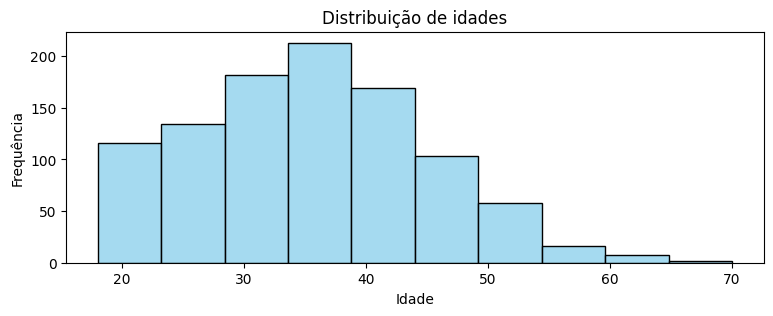

In [8]:
# Verificando a distribuição de idades via histograma
plt.figure(figsize=(9, 3))
sns.histplot(data=df, x='idade', bins=10, color='skyblue')
plt.title('Distribuição de idades')
plt.xlabel('Idade')
plt.ylabel('Frequência')
plt.show()

In [9]:
# Calculando o coeficiente de variabilidade
CV = round((df.idade.std() / df.idade.mean()) * 100, 1)
CV

np.float64(27.0)

Analisando a variável quantitativa discreta **Idade**, podemos observar uma cauda mais alongada à direita, indicando uma leve assimetria positiva. Isso significa que a maior parte dos clientes está concentrada em idades mais baixas ou intermediárias, enquanto existe uma quantidade menor de clientes com idades mais elevadas. Além disso, o desvio padrão de 9,5 anos e CV de 27% indicam que as idades apresentam uma variação relativamente moderada em torno da média. Não estamos diante de uma base formada exclusivamente por clientes com idades muito proximas. Apesar da concentração entre 30 e 35 anos, a base contempla clientes mais jovens e mais velhos. Portanto, é importante investigar se a ocorrência de problemas críticos está distribuida igualmene entre essas faixas.

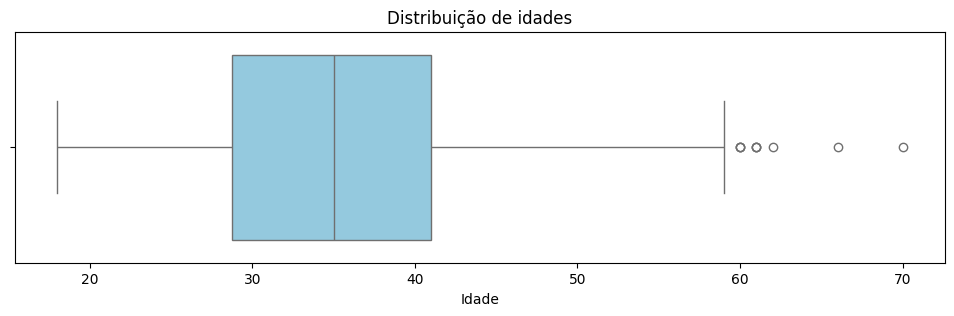

In [10]:
# Verificando a distribuição de idades via boxplot para identificar outliers
plt.figure(figsize=(12, 3))
sns.boxplot(data=df, x='idade', color='skyblue')
plt.title('Distribuição de idades')
plt.xlabel('Idade')
plt.show()

Os outliers estão concentrados na extremidade superior da distribuição, reforçando a presença de uma pequena parcela de clientes com idade mais avançada. Considerando o problema de negócio identificado, esses clientes mais velhos apresentam mais problemas criticos?  

In [11]:
# Exibindo as estatísticas descritivas básicas de idade para ambos os grupos
display(df.groupby('problema_critico')['idade'].describe())

,count,mean,std,min,25%,50%,75%,max
problema_critico,,,,,,,,
0,950.0,35.434737,9.506332,18.0,29.0,35.0,41.0,70.0
1,50.0,33.220000,9.765182,18.0,26.0,32.0,41.5,57.0


Os clientes que reportaram problemas criticos apresentam uma idade média e mediana ligeiramente inferiores às dos clientes que não reportaram problemas.Isso indica uma concentração um pouco maior dos clientes mais jovens entre aqueles que tiveram problemas críticos, mas ainda não podemos afirmar que os cliente mais jovens são mais vulneráveis. Além disso, os desvios padrão são muito próximos, o que significa que a dispersão das idades é relativamente semelhante, embora seja ligeiramente maior entre os clientes que reportaram problemas. Em outras palavras, os clientes que tiveram problemas não apresentam uma concentração etária muito diferente em termos de variabilidade.

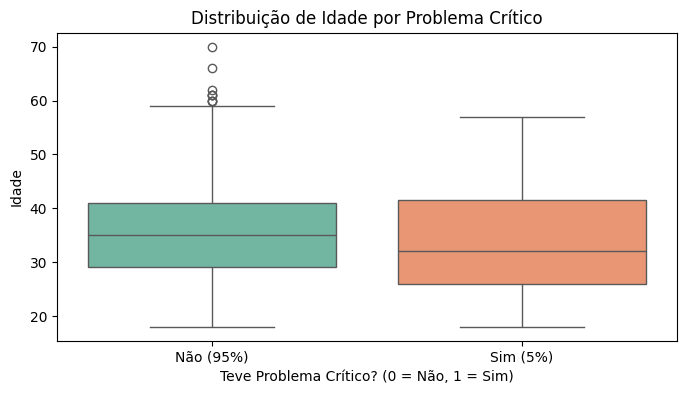

In [12]:
# Comparando a distribuição de idade entre quem teve e não teve problemas críticos via boxplot
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='problema_critico', y='idade', hue='problema_critico', palette='Set2', legend=False)
plt.title('Distribuição de Idade por Problema Crítico')
plt.xlabel('Teve Problema Crítico? (0 = Não, 1 = Sim)')
plt.ylabel('Idade')
plt.xticks([0, 1], ['Não (95%)', 'Sim (5%)'])
plt.show()

Analisando o boxplot, verificamos que os outliers que identificamos anteriormente aparecem no grupo que não teve problemas críticos. Isso significa que os clientes mais velhos identificados como outliers não estão concentrados no grupo que reportou problemas.

In [13]:
# Calculando o CV para ambos os grupos
CV_nao = df[df['problema_critico'].eq(0)]['idade'].std() / df[df['problema_critico'].eq(0)]['idade'].mean()
CV_sim = df[df['problema_critico'].eq(1)]['idade'].std() / df[df['problema_critico'].eq(1)]['idade'].mean()

print(f'CV não teve problema crítico: {round(CV_nao * 100, 1)}%')
print(f'CV teve problema crítico: {round(CV_sim * 100, 1)}%')

CV não teve problema crítico: 26.8%
CV teve problema crítico: 29.4%


O CV mostra que as idades dos clientes que tiveram problemas críticos apresentam uma variabilidade relativa um pouco maior. Isso significa que esse grupo apresenta uma distribuição etária um pouco mais heterogênea em relação à sua própria média.

Consolidando os insights da variável Idade:

*   A maior concentração de clientes está entre 30 e 45 anos, com idade média de 35,32 anos.
*   A distribuição apresenta uma cauda à direita, com poucos clientes em faixas etárias mais elevadas.
*   Clientes com problemas críticos apresentam média de idade de 33,22 anos, contra 35,43 anos entre aqueles sem problemas.
*   Os desvios padrão são próximos (9,77 e 9,51 anos), indicando variabilidade semelhante entre os grupos.
*   Existe uma sobreposição considerável entre as distribuições de idade dos dois grupos. Portanto, a idade isoladamente ainda não demonstra ser um fator claramente associado à ocorrência de problemas críticos.


In [14]:
# Criando faixas etárias
df['faixa_etaria'] = pd.cut(df['idade'],bins=[17, 24, 34, 44, 54, float('inf')],labels=['18-24','25-34','35-44', '45-54','55+'])

# Agrupando os clientes
analise_idade = df.groupby('faixa_etaria',observed=True).agg(total_clientes=('id_cliente', 'count'),clientes_com_problema=('problema_critico', 'sum'))

# Calculando a taxa de problemas
analise_idade['taxa_problemas'] = ( analise_idade['clientes_com_problema'] / analise_idade['total_clientes']) * 100

display(analise_idade)

,total_clientes,clientes_com_problema,taxa_problemas
faixa_etaria,,,
18-24,135,9,6.666667
25-34,332,19,5.722892
35-44,366,17,4.644809
45-54,142,4,2.816901
55+,25,1,4.000000


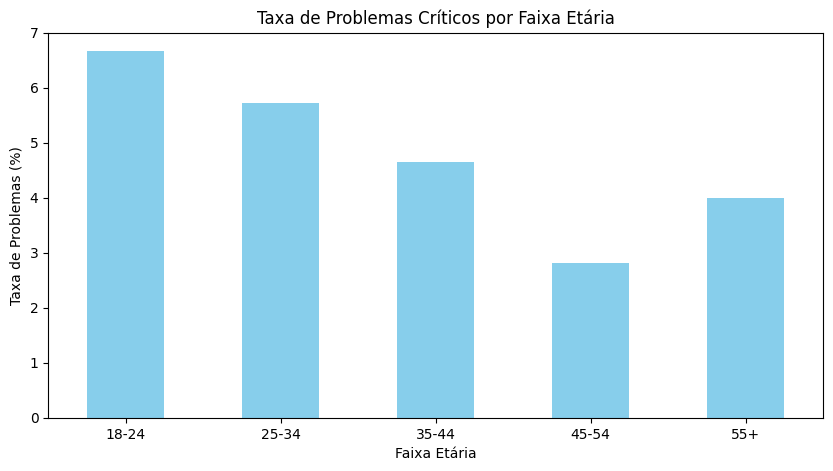

In [15]:
analise_idade['taxa_problemas'].plot(kind='bar',figsize=(10, 5),color='skyblue')

plt.title('Taxa de Problemas Críticos por Faixa Etária')
plt.xlabel('Faixa Etária')
plt.ylabel('Taxa de Problemas (%)')
plt.xticks(rotation=0)
plt.show()

A análise da incidência de problemas críticos por faixa etária identificou diferenças entre os grupos de clientes. A maior taxa foi observada entre os clientes de **18 a 24 anos**, com 6,67%, seguida pela faixa de **25 a 34 anos**, com 5,72%. Em contrapartida, os clientes entre **45 e 54 anos** apresentaram a menor taxa, de 2,82%. Os resultados sugerem uma possível maior vulnerabilidade dos clientes mais jovens à ocorrência de problemas críticos. Entretanto, essa associação ainda precisa ser investigada, considerando o tamanho dos grupos e outras características dos usuários.

### **Uso mensal**

In [16]:
df.uso_mensal.describe()

,uso_mensal
count,1000.000000
mean,17.941000
std,4.195846
min,7.000000
25%,15.000000
50%,18.000000
75%,21.000000
max,33.000000


In [17]:
# Calculando o CV
CV_uso = round(df.uso_mensal.std() / df.uso_mensal.mean() * 100, 2)
print(f'{CV_uso} %')

23.39 %


Observamos que a média (17,94) e a mediana (18) são praticamente iguais. Isso indica que o centro da distribuição está bem próximo de 18 utilizações. Não temos, aparentemente, uma grande influência de valores extremos deslocando a média. Além disso, o CV de 23,4% indica uma variabilidade moderada dos dados.

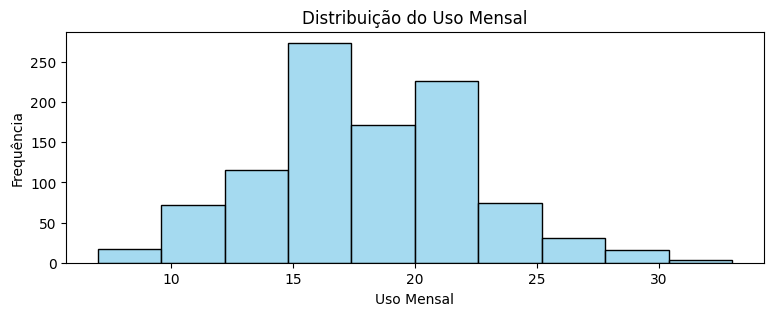

In [18]:
# Verificando a distribuição por histograma
plt.figure(figsize=(9, 3))
sns.histplot(data=df, x='uso_mensal', bins=10, color='skyblue')
plt.title('Distribuição do Uso Mensal')
plt.xlabel('Uso Mensal')
plt.ylabel('Frequência')
plt.show()

Podemos observar que a maior concentração está entre aproximadamente 15 e 22 utilizações mensais, existem poucos clientes com frequência muito baixa, existem poucos clientes com frequência muito elevada e distribuição parece relativamente concentrada em torno da média, embora apresente pequenas irregularidades.

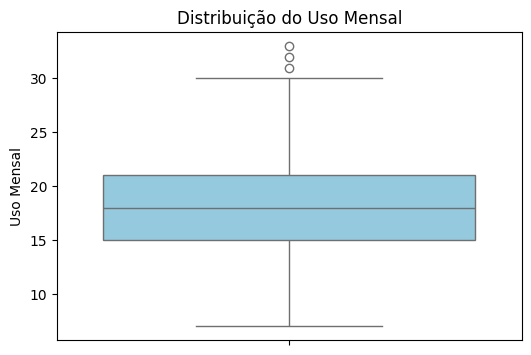

In [19]:
# Verificando a distribuição por boxplot
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, y='uso_mensal', color='skyblue')
plt.title('Distribuição do Uso Mensal')
plt.ylabel('Uso Mensal')
plt.show()

Foram identificados três possíveis outliers superiores, com frequência acima de 30 utilizações mensais.

**Os clientes que tiveram problemas críticos apresentam um comportamento de utilização diferente daqueles que não tiveram problemas?**

In [20]:
# criando uma tabela de estatisticas descritivas para ambos os grupos
display(df.groupby('problema_critico')['uso_mensal'].describe())

,count,mean,std,min,25%,50%,75%,max
problema_critico,,,,,,,,
0,950.0,17.986316,4.226070,7.0,15.0,18.0,21.00,33.0
1,50.0,17.080000,3.498338,10.0,15.0,17.0,19.75,24.0


A média dos clientes sem problemas críticos é 17,99, enquanto a dos clientes com problemas é 17,08. Isso significa que, em média, os clientes que tiveram problemas críticos utilizam o aplicativo um pouco menos. Essa diferença é pequena, então não temos evidências suficientes para afirmar que a frequência de utilização seja um fator importante na ocorrência dos problemas. Além disso, o grupo que apresentou problemas críticos possui menor dispersão. Em palavras simples, os clientes desse grupo apresentam frequências de utilização um pouco mais concentradas em torno da média. Isso também aparece nos quartis: 50% dos clientes sem problemas estão entre 15 e 21 utilizações, enquanto, no grupo com problemas, estão entre 15 e 19,75.

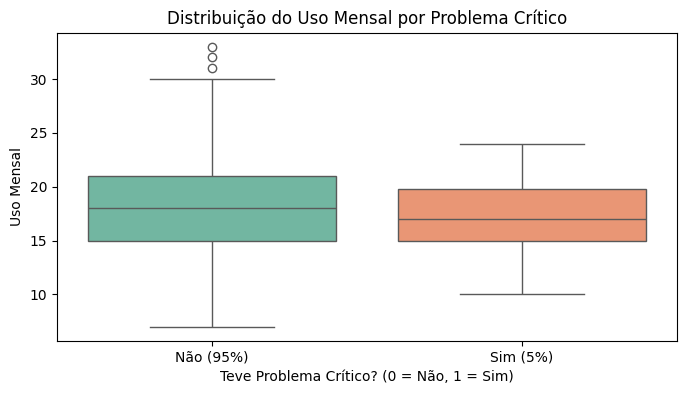

In [21]:
# criando um boxplot comparativo
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='problema_critico', y='uso_mensal', hue='problema_critico', palette='Set2', legend=False)
plt.title('Distribuição do Uso Mensal por Problema Crítico')
plt.xlabel('Teve Problema Crítico? (0 = Não, 1 = Sim)')
plt.ylabel('Uso Mensal')
plt.xticks([0, 1], ['Não (95%)', 'Sim (5%)'])
plt.show()

Observamos que os outliers aparecem no grupo que não apresentou problemas críticos. Isso significa que alguns clientes utilizam o aplicativo com frequência bastante elevada, chegando a 33 utilizações mensais. Já no grupo com problemas críticos, o máximo observado foi 24. É uma observação interessante: nesta base, não encontramos clientes com problemas críticos entre os usuários de frequência mais elevada.

**A proporção de clientes com problemas críticos é maior em determinadas faixas de utilização do aplicativo?**

In [22]:
# Criando as faixas de utilização mensal
df['faixa_uso'] = pd.cut(df['uso_mensal'],bins=[0, 10, 15, 20, 25, float('inf')],labels=['Até 10', '11 a 15', '16 a 20', '21 a 25', 'Acima de 25'])

# Agrupando os clientes e calculando as métricas por faixa de uso
analise_uso = df.groupby('faixa_uso', observed=True).agg(total_clientes=('id_cliente', 'count'),clientes_com_problema=('problema_critico', 'sum'))

# Calculando a taxa de problemas críticos em percentual
analise_uso['taxa_problemas'] = (analise_uso['clientes_com_problema'] / analise_uso['total_clientes']) * 100

# Exibindo a tabela resultante
display(analise_uso)

,total_clientes,clientes_com_problema,taxa_problemas
faixa_uso,,,
Até 10,34,2,5.882353
11 a 15,256,16,6.250000
16 a 20,449,23,5.122494
21 a 25,211,9,4.265403
Acima de 25,50,0,0.000000


1. A faixa de 11 a 15 utilizações mensais apresentou a maior incidência de problemas críticos, com taxa de 6,25%, acima da média geral de 5%.

2. Observou-se uma tendência de redução na taxa de problemas críticos conforme aumenta a frequência de utilização, especialmente a partir da faixa de 11 a 15 utilizações.

3. Apesar de apresentar a maior taxa, a faixa de 11 a 15 não concentra a maior quantidade de ocorrências. A faixa de 16 a 20 reúne 23 dos 50 clientes com problemas críticos.

A frequência de utilização pode ser uma característica relevante para segmentar os clientes durante a investigação, especialmente aqueles que utilizam o aplicativo até 15 vezes por mês. Entretanto, ainda não temos evidências suficientes para afirmar que a baixa frequência aumenta o risco de problemas críticos.

### **Nota de Experiência**

In [23]:
df.nota_experiencia.describe()

,nota_experiencia
count,1000.000000
mean,8.066100
std,1.453077
min,0.200000
25%,7.300000
50%,8.300000
75%,9.100000
max,10.000000


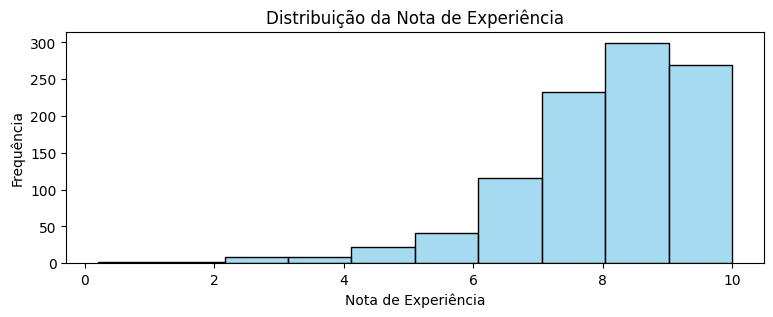

In [24]:
# Criando grafico de histograma para verificar a distribuição de nota de experiencia
plt.figure(figsize=(9, 3))
sns.histplot(data=df, x='nota_experiencia', bins=10, color='skyblue')
plt.title('Distribuição da Nota de Experiência')
plt.xlabel('Nota de Experiência')
plt.ylabel('Frequência')
plt.show()

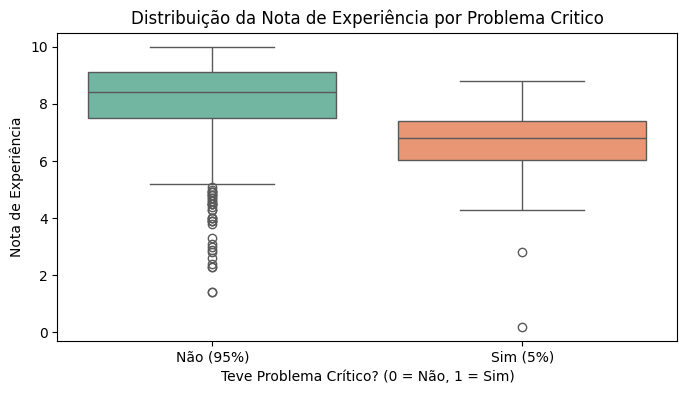

In [25]:
# criando boxplot para comparar os grupos com a nota de experiencia
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='problema_critico', y='nota_experiencia', hue='problema_critico', palette='Set2', legend=False)
plt.title('Distribuição da Nota de Experiência por Problema Critico')
plt.xlabel('Teve Problema Crítico? (0 = Não, 1 = Sim)')
plt.ylabel('Nota de Experiência')
plt.xticks([0, 1], ['Não (95%)', 'Sim (5%)'])
plt.show()

In [26]:
display(df.groupby('problema_critico')['nota_experiencia'].describe())

,count,mean,std,min,25%,50%,75%,max
problema_critico,,,,,,,,
0,950.0,8.148737,1.405819,1.4,7.500,8.4,9.1,10.0
1,50.0,6.496000,1.457137,0.2,6.025,6.8,7.4,8.8


1. Clientes que reportaram problemas críticos apresentam uma mediana de nota de experiência inferior à dos clientes que não reportaram problemas.

2. A distribuição das avaliações dos clientes com problemas críticos está concentrada em notas menores, sugerindo uma associação entre a ocorrência de falhas e uma pior percepção da experiência.

3. Foram identificados outliers inferiores nos dois grupos, indicando que também existem clientes com avaliações muito baixas mesmo sem terem reportado problemas críticos.

Ou seja, a ocorrência de problemas críticos está associada a uma pior avaliação da experiência. Portanto, a força-tarefa de melhoria deve considerar tanto a prevenção de falhas quanto a recuperação da experiência dos clientes afetados.

### **Tempo de resposta**

In [27]:
df.tempo_resposta_min.describe()

,tempo_resposta_min
count,1000.000000
mean,13.055300
std,9.897175
min,3.000000
25%,5.800000
50%,10.300000
75%,16.725000
max,60.000000


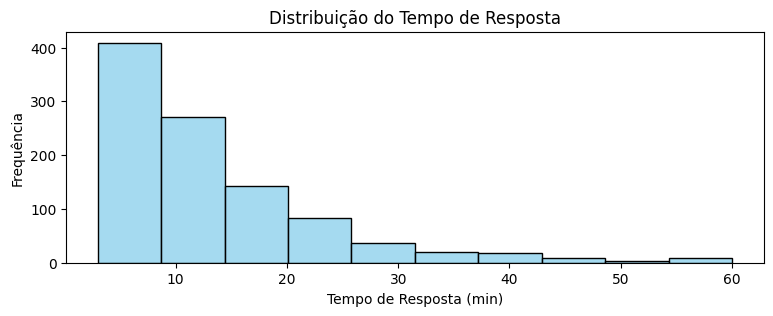

In [28]:
# criando grafico de histograma para verificar a distribuição
plt.figure(figsize=(9, 3))
sns.histplot(data=df, x='tempo_resposta_min', bins=10, color='skyblue')
plt.title('Distribuição do Tempo de Resposta')
plt.xlabel('Tempo de Resposta (min)')
plt.ylabel('Frequência')
plt.show()

O tempo médio de resposta foi de 13,1 minutos, enquanto a mediana foi de 10,3 minutos. Como a média é superior à mediana, há evidências de uma assimetria positiva, indicando que alguns atendimentos com tempos muito elevados puxam a média para cima. De fato, 50% dos atendimentos ocorreram entre 5,8 minutos (1º quartil) e 16,7 minutos (3º quartil), mostrando que a maior parte dos clientes recebeu resposta em um intervalo relativamente curto. No entanto, existem casos extremos que chegam a 60 minutos, evidenciando uma cauda longa na distribuição.

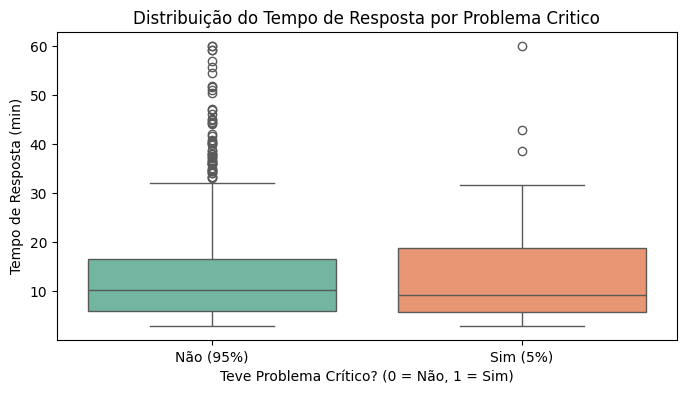

In [29]:
# analisando a distribuição via boxplot comparando os grupos
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='problema_critico', y='tempo_resposta_min', hue='problema_critico', palette='Set2', legend=False)
plt.title('Distribuição do Tempo de Resposta por Problema Critico')
plt.xlabel('Teve Problema Crítico? (0 = Não, 1 = Sim)')
plt.ylabel('Tempo de Resposta (min)')
plt.xticks([0, 1], ['Não (95%)', 'Sim (5%)'])
plt.show()

A análise do boxplot evidencia a presença de diversos outliers nos tempos de resposta, especialmente acima de 30 minutos. Embora a maior parte dos atendimentos ocorra em menos de 17 minutos, existe uma pequena parcela de clientes que enfrenta tempos de espera substancialmente maiores. Isso sugere que o processo de suporte é eficiente para a maioria dos casos, mas apresenta episódios pontuais de atraso que merecem investigação. A identificação das causas desses atendimentos extremos pode representar uma importante oportunidade de melhoria na consistência e qualidade do serviço prestado.

In [30]:
display(df.groupby('problema_critico')['tempo_resposta_min'].describe())

,count,mean,std,min,25%,50%,75%,max
problema_critico,,,,,,,,
0,950.0,13.027684,9.81061,3.0,5.900,10.3,16.60,60.0
1,50.0,13.580000,11.51946,3.0,5.725,9.2,18.75,60.0


Os chamados classificados como críticos tendem a receber atendimento mais rapidamente na maior parte dos casos (mediana menor). Porém, quando ocorrem atrasos, eles tendem a ser mais severos, elevando a média do grupo.

In [31]:
# calculando o CV de tempo de resposta para cada grupo
CV_nao = df[df['problema_critico'].eq(0)]['tempo_resposta_min'].std() / df[df['problema_critico'].eq(0)]['tempo_resposta_min'].mean()
CV_sim = df[df['problema_critico'].eq(1)]['tempo_resposta_min'].std() / df[df['problema_critico'].eq(1)]['tempo_resposta_min'].mean()

print(f'CV não teve problema crítico: {round(CV_nao * 100, 1)}%')
print(f'CV teve problema crítico: {round(CV_sim * 100, 1)}%')

CV não teve problema crítico: 75.3%
CV teve problema crítico: 84.8%


O grupo de clientes que enfrentou problemas críticos apresentou maior variabilidade no tempo de resposta (CV = 84,8%) em comparação ao grupo sem problemas críticos (CV = 75,3%). Isso sugere menor previsibilidade no atendimento dos casos críticos. Em outras palavras, embora muitos chamados críticos sejam atendidos rapidamente, existe uma dispersão maior, fazendo com que alguns casos demorem significativamente mais que outros.

Ou seja, uma oportunidade de melhoria seria investigar os poucos casos com tempos de resposta extremamente elevados, especialmente entre os chamados críticos, para identificar gargalos e aumentar a previsibilidade do atendimento.

### **Análise Cruzada**

Faixa Etária x Nota de experiência

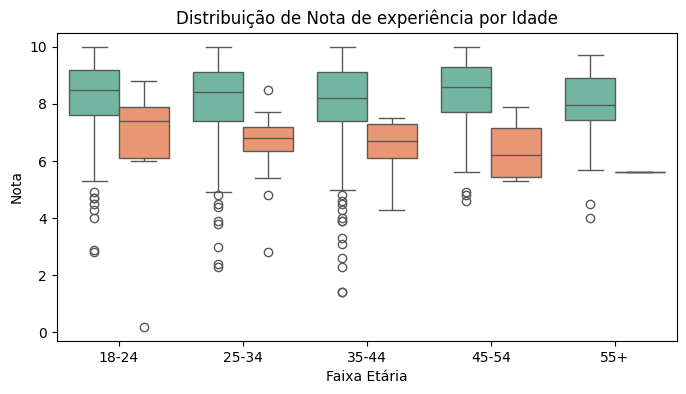

In [51]:
# visualizando por boxplot
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='faixa_etaria', y='nota_experiencia', hue='problema_critico', palette='Set2', legend=False)
plt.title('Distribuição de Nota de experiência por Idade')
plt.xlabel('Faixa Etária')
plt.ylabel('Nota')
plt.show()



*   **Queda Consistente da Mediana:** Em absolutamente todas as faixas etárias, os clientes que enfrentaram um problema critico (box laranja) apresentam mediana e quartis de nota significativamente menores em relação aos que não tiveram problemas (box verde).
*    **Punição Severa no Público Jovem (18–24 anos):** O grupo de 18 a 24 anos apresenta a maior penalização absoluta na avaliação, registrando a menor mediana de nota sob falha (próxima de 7,4, mas com limite inferior atingindo próximo a 6,0 e um outlier próximo de 0).
*  **Degradadação Progressiva (25 a 54 anos):** As faixas de 25-34, 35-44 e 45-54 anos mostram quedas acentuadas na mediana das notas quando ocorre um problema crítico, caindo de faixas de 8,2–8,5 para a faixa de 6,2–6,8.
*  **Insatisfação Residual sem Falha Registrada:** Mesmo na ausência de problema crítico (box verde), há uma quantidade considerável de outliers com notas muito baixas (entre 1 e 5) concentrados de 18 a 44 anos, indicando fricções de usabilidade que não chegam a ser registradas como chamados/erros críticos formais.



      

Faixa Etária x Uso Mensal

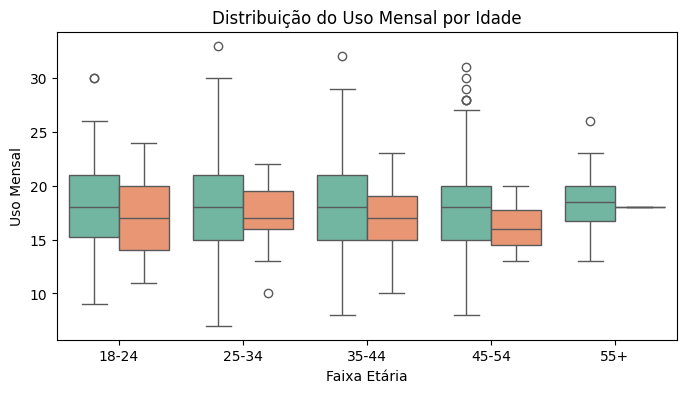

In [52]:
# visualizando por boxplot
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='faixa_etaria', y='uso_mensal', hue='problema_critico', palette='Set2', legend=False)
plt.title('Distribuição do Uso Mensal por Idade')
plt.xlabel('Faixa Etária')
plt.ylabel('Uso Mensal')
plt.show()



*   **Distribuição Homogênea:** A distribuição da frequência de uso mensal (mediana e intervalo interquartil) é extremamente semelhante entre o grupo com falha (laranja) e sem falha (verde) em todas as faixas etárias.   
*   **Ausência de Efeito de Engajamento:** Clientes que usam a plataforma com alta frequência (20 a 30 acessos/mês) sofrem problemas na mesma proporção que usuários casuais. O problema crítico não atinge desproporcionalmente quem usa mais ou menos; ele afeta a experiência de forma independente do volume de uso.   


## **Decisão Recomendada:**
Priorizar a força-tarefa de Usabilidade, Estabilidade e Suporte focada nos públicos de 18 a 34 anos, combinando correção técnica imediata com revisão das jornadas de suporte rápido no produto.

### Fundamentação por Evidências Estatísticas:
1. Maior Taxa de Incidência + Maior Penalização (18–34 anos): Os dados anteriores demonstraram maior proporção de problemas críticos nos jovens (6,67% em 18–24 e 5,72% em 25–34 vs. 2,82% em 45–54). Os boxplots atuais provam que este mesmo público pune a empresa com as piores notas absolutas e maior amplitude de queda quando a falha ocorre.   

2. Desconexão com Volume de Uso: Como o uso_mensal não previne nem precipita o erro, direcionar esforços com base na frequência de uso não trará retorno de satisfação. A priorização por faixa etária vulnerável é estatisticamente mais eficaz.   

3. Fricção Invisível na Usabilidade: A presença de outliers com notas baixas no grupo sem erro crítico indica que UX/UI confusa afeta o público mais jovem antes mesmo do surgimento de um bug no sistema.   

### Plano de Ação Executivo:
**Fase 1:** Alocar a força-tarefa nos fluxos mais utilizados por clientes de 18–34 anos para erradicar gargalos operacionais e erros críticos.

**Fase 2:** Reduzir o tempo de resposta do suporte para incidentes críticos nesse perfil de idade, amortecendo a perda imediata de nota.

**Fase 3:** Investigar e simplificar os fluxos da plataforma para eliminar as fricções silenciosas apontadas pelos outliers de baixa nota no público geral.   